# Data visualisation

R-only visualisation of the frozen experiment data: CE (ggcube), SIC (tmap), and GVI (tmap).
SHP is deliberately omitted.
Plots are displayed inline only: this notebook does not export figures, tables, or data files.
All observations and all fixed partitions are shown together; these are data illustrations, not model predictions.


## Preparation

In [84]:
library(tidyverse)
library(ggcube)
library(sf)
library(tmap)
library(viridisLite)
library(patchwork)
options(repr.plot.res=130, repr.plot.width=10, repr.plot.height=8)
theme_set(theme_minimal(base_size=18, base_family = "Times New Roman"))
scripts_dir <- normalizePath(".")
stopifnot(length(scripts_dir) == 1)
repository_dir <- dirname(dirname(scripts_dir))

In [81]:
options(
    bitmapType = "cairo",
    jupyter.plot_mimetypes = "image/png"
)

## Read the frozen inputs

A tidyverse pipeline enumerates the required arrays, decodes them with `purrr::map2()`, and combines the observations into a tidy tibble.
Low-level ZIP/NPY binary reading remains in base R and preserves C/Fortran storage order.
Data transformation uses `%>%`, dplyr, tidyr, stringr and purrr; Python and reticulate are not required.


In [6]:
raw_arrays <- crossing(case = c("CE", "SIC", "GVI"), array = c("u_raw", "actual")) %>%
  mutate(
    archive_path = file.path(scripts_dir, "data", case, "ordinary.npz"),
    values = map2(archive_path, array, ~ {
      connection <- unz(.x, paste0(.y, ".npy"), open = "rb")
      on.exit(close(connection), add = TRUE)
      magic <- readBin(connection, what = "raw", n = 6)
      stopifnot(identical(magic, as.raw(c(0x93, utf8ToInt("NUMPY")))))
      version <- readBin(connection, what = "integer", n = 2, size = 1, signed = FALSE)
      stopifnot(version[1] %in% c(1, 2))
      header_size <- readBin(connection,
        what = "integer", n = 1,
        size = if (version[1] == 1) 2 else 4,
        signed = (version[1] != 1), endian = "little"
      )
      header <- rawToChar(readBin(connection, what = "raw", n = header_size))
      stopifnot(str_detect(header, fixed("'descr': '<f8'")))
      shape_text <- str_match(header, "'shape': \\(([^)]*)\\)")[, 2]
      dimensions <- str_split(shape_text, ",")[[1]] %>%
        str_trim() %>%
        discard(~ .x == "") %>%
        as.integer()
      values <- readBin(connection, what = "double", n = prod(dimensions), size = 8, endian = "little")
      stopifnot(length(values) == prod(dimensions), all(is.finite(values)))
      if (length(dimensions) == 2) {
        fortran_order <- str_detect(header, fixed("'fortran_order': True"))
        values <- matrix(values, nrow = dimensions[1], ncol = dimensions[2], byrow = !fortran_order)
      }
      values
    })
  ) %>%
  select(case, array, values) %>%
  pivot_wider(names_from = array, values_from = values)

observations <- raw_arrays %>%
  transmute(case, data = map2(u_raw, actual, ~ {
    as_tibble(.x, .name_repair = "minimal") %>%
      set_names(paste0("coordinate_", seq_len(ncol(.x)))) %>%
      mutate(response = .y)
  })) %>%
  unnest(data)


## CE — space–time cube

The horizontal axes retain the supplied planar coordinates; the vertical axis is year. Colour represents the stored CO₂ response, whose physical unit and upstream transformation are unspecified.

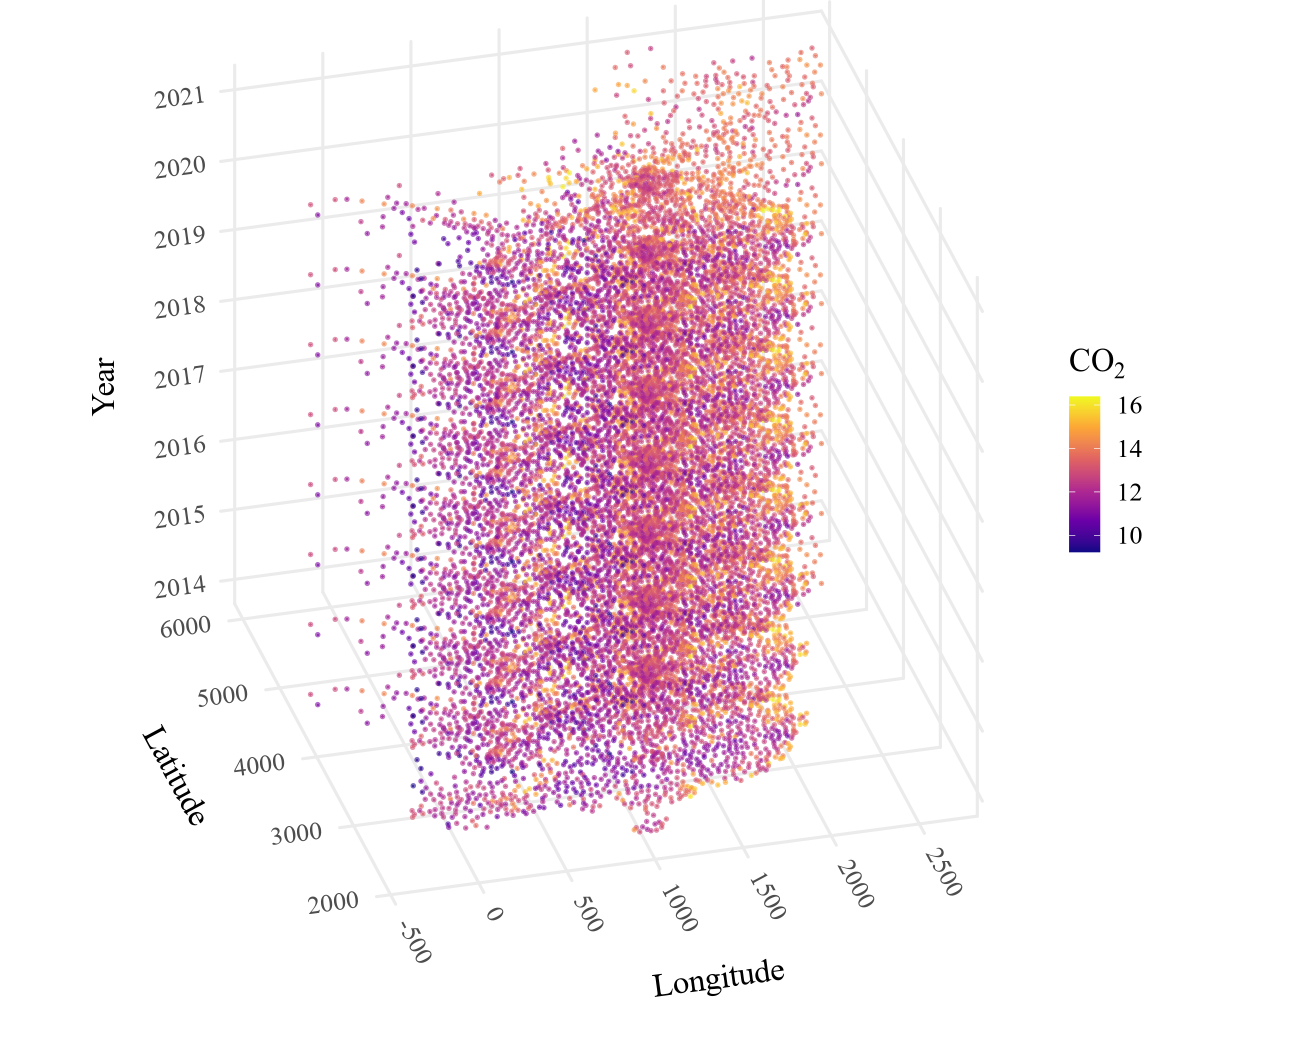

In [184]:
ce <- observations %>%
  filter(case == "CE") %>%
  transmute(u = coordinate_1, v = coordinate_2, year = coordinate_3, response)

fig_ce <- ce %>%
  ggplot(ggcube::aes(x = u, y = v, z = year, colour = response)) +
  geom_point_3d(size = .6, alpha = .6, scale_depth = FALSE) +
  scale_colour_viridis_c(option = "C") +
  scale_z_continuous(breaks = 2014:2021) +
  coord_3d(
    pitch = 0, roll = -60, yaw = -15, ratio = c(1, 1, 1), clip = "off",
    persp = FALSE
  ) +
  labs(x = "Longitude", y = "Latitude", z = "Year", color = expression(CO[2])) +
  theme(
    legend.position = "right",
    plot.margin = margin(-1,0,1,0, unit = "cm"),
  )
fig_ce

## SIC — observed origin–destination flows

All 13,807 positive-flow observations are drawn as origin–destination lines on the supplied Wuhan subdistrict boundaries. Line colour uses fixed count classes (1–9, 10–99, 100–999, 1,000–9,999, and 10,000 or more); low-count lines are drawn first. Coordinates are transformed from EPSG:3857 into metric UTM zone 50N. These are raw observed counts, not log-transformed training targets.

In [22]:
wuhan_path <- file.path(repository_dir, 'data/OD-Wuhan/wuhan_subdis.gpkg')
if (!file.exists(wuhan_path)) {
    wuhan_path <- file.path(scripts_dir, 'data/SHP/wuhan_subdis.gpkg')
}
wuhan <- st_read(wuhan_path, quiet=TRUE) %>%
    st_make_valid() %>%
    st_transform(32650)

In [24]:
sic <- observations %>%
    filter(case == 'SIC') %>%
    transmute(origin_x=coordinate_1, origin_y=coordinate_2,
              destination_x=coordinate_3, destination_y=coordinate_4, response) %>%
    arrange(response)

In [25]:
sic_flows <- sic %>%
    transmute(
        response,
        geometry=pmap(list(origin_x, origin_y, destination_x, destination_y),
            ~ st_linestring(matrix(c(..1, ..2, ..3, ..4), ncol=2, byrow=TRUE)))
    ) %>%
    mutate(geometry=st_sfc(geometry, crs=3857)) %>%
    st_as_sf() %>%
    st_transform(32650)

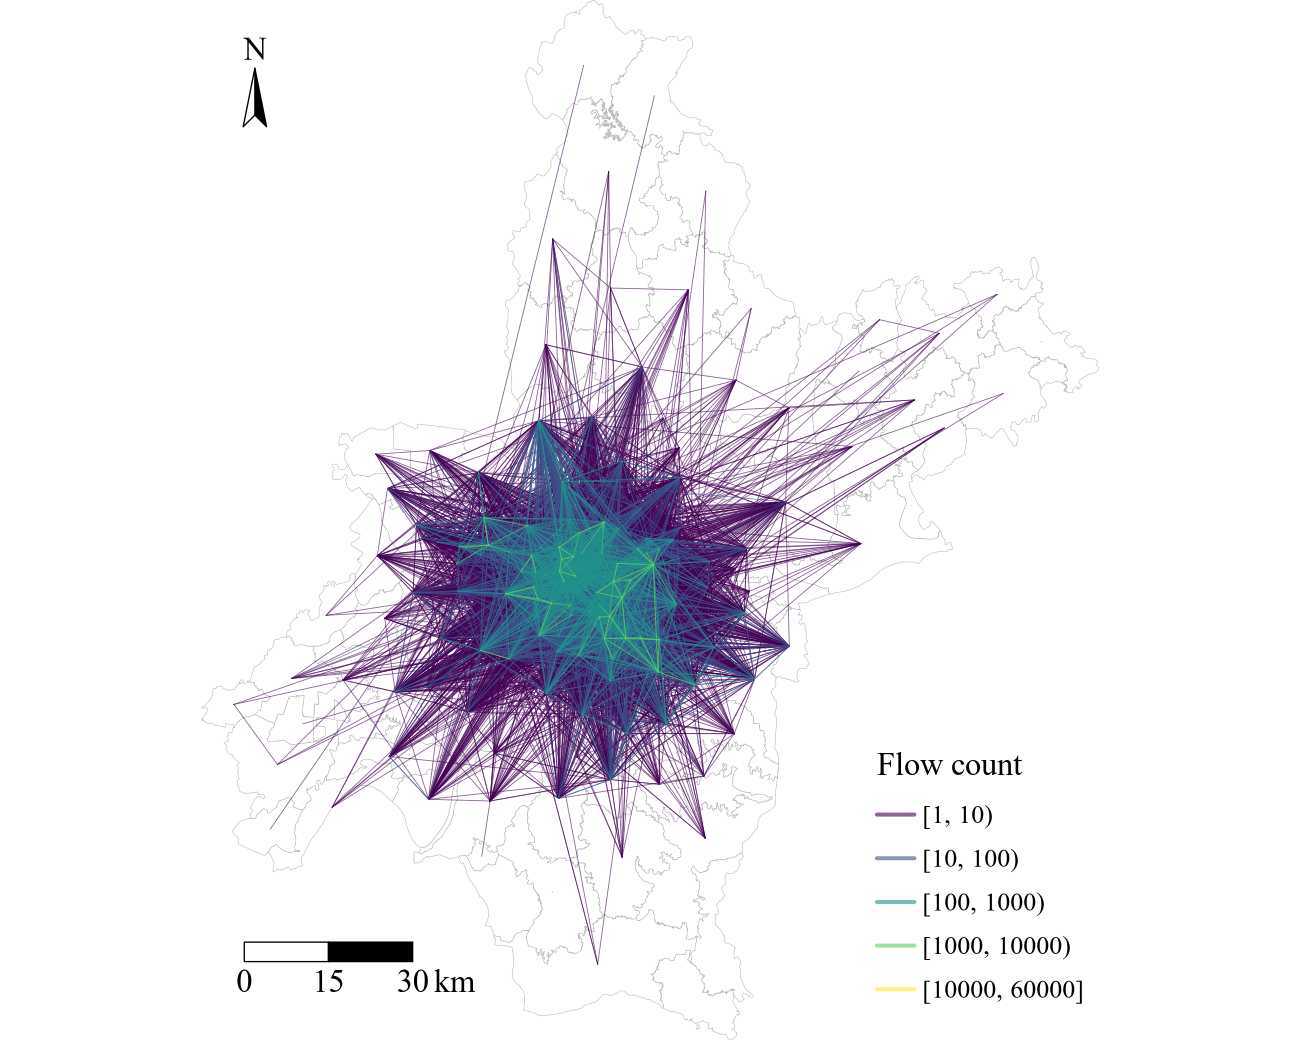

In [158]:
fig_sic <- tm_shape(wuhan, unit = "km") +
  tm_polygons(fill = "white", col = "#B5B5B5", lwd = .4) +
  tm_shape(sic_flows) +
  tm_lines(
    col = "response", lwd = .65, col_alpha = .6,
    col.scale = tm_scale_intervals(
      breaks = c(1, 10, 100, 1000, 10000, 60000),
      values = viridis(5, option = "D"),
      label.format = tm_label_format(scientific = TRUE, format = "f")
    ),
    col.legend = tm_legend(
      title = "Flow count", frame = FALSE, title.size = 1.5, text.size = 1.2,
      position = tm_pos_in("right", "bottom"),
      lwd = 3
    )
  ) +
  tm_compass(
    position = tm_pos_in("left", "top"), size = 1.5,
    text.size = 1.5
  ) +
  tm_scalebar(
    breaks = c(0, 15, 30),
    position = tm_pos_in("left", "bottom"),
    text.size = 1.5
  ) +
  tm_layout(
    frame = FALSE,
    inner.margins = c(0, 0, 0, 0),
    outer.margins = c(0, 0, 0, 0),
    text.fontfamily = "Times New Roman"
  )
fig_sic

## GVI — Shanghai observations

Point colour shows observed GVI in five fixed classes over its [0,1] range.
The projected observation coordinates use EPSG:32651, as recorded in the data contract.
Shanghai's municipal boundary is embedded below so this notebook needs no online basemap request during execution.
Boundary source: [geoBoundaries CHN ADM1](https://www.geoboundaries.org/api/current/gbOpen/CHN/ADM1/), represented year 2019, Public Domain; frozen release commit `9469f09`, feature `Shanghai Municipality`.
The simplified boundary is a contextual basemap, not an analytical mask; no observations are removed.


In [50]:
shanghai <- st_read("data/GVI/shanghai_county.geojson", quiet = TRUE) %>%
  st_make_valid() %>%
  st_transform(32651)

In [37]:
gvi <- observations %>%
  filter(case == "GVI") %>%
  transmute(x = coordinate_1, y = coordinate_2, response)
gvi_points <- gvi %>%
  st_as_sf(coords = c("x", "y"), crs = 32651)

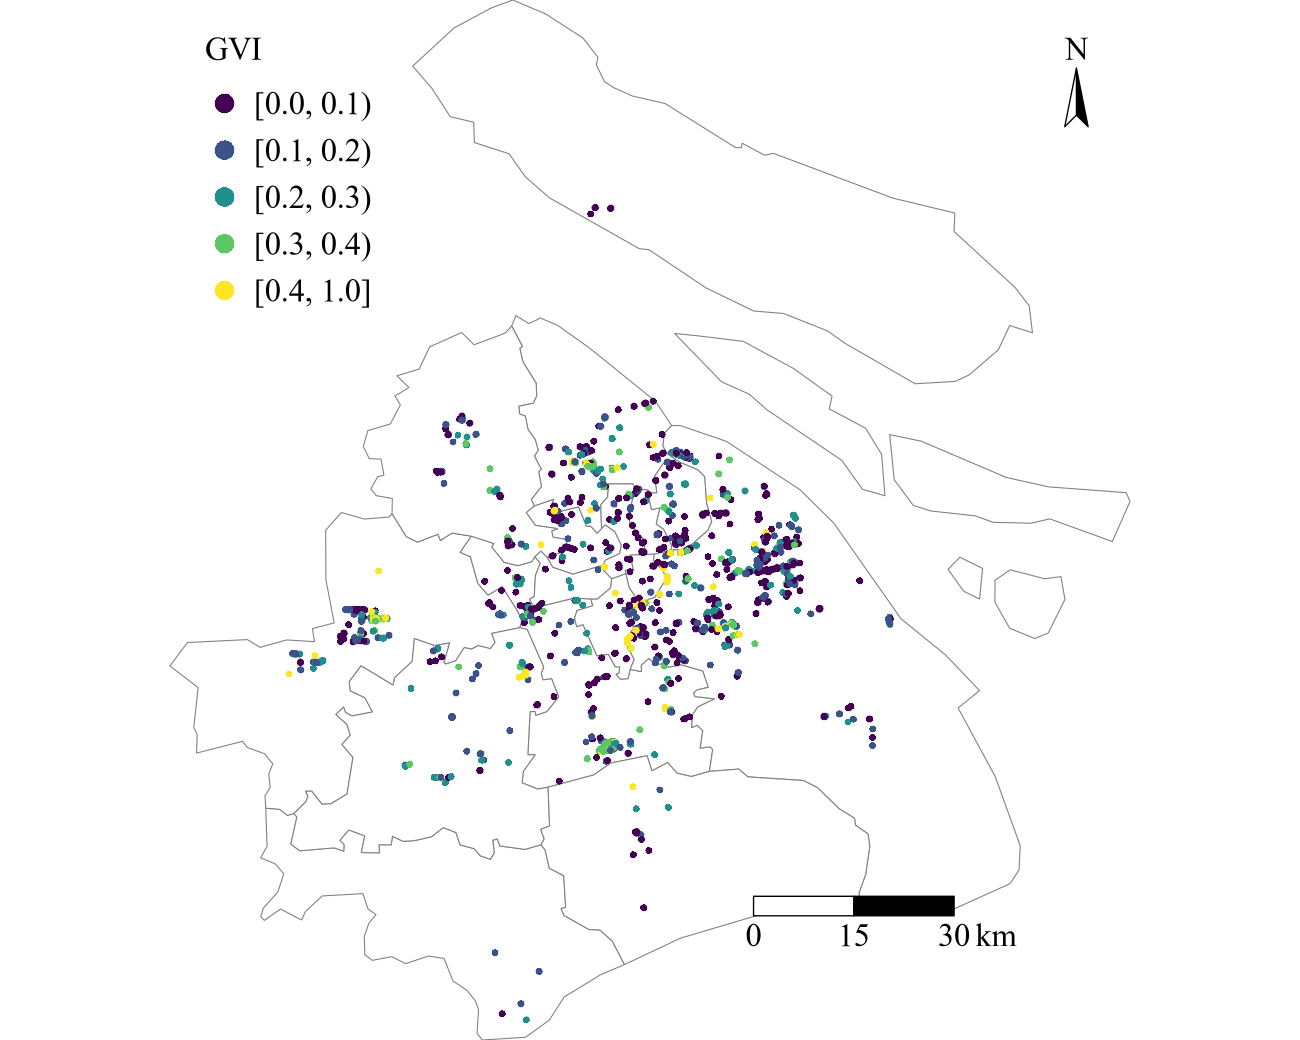

In [229]:
fig_gvi <- tm_shape(shanghai) +
  tm_polygons(fill = "white", col = "#808080", lwd = .8) +
  tm_shape(gvi_points) +
  tm_dots(
    fill = "response", size = .35, col = "white", lwd = .1,
    fill.scale = tm_scale_intervals(
      breaks = c(0, .1, .2, .3, .4, 1),
      values = viridis(5, option = "D"),
      label.format = tm_label_format(scientific = TRUE, format = "f")
    ),
    fill.legend = tm_legend(
      title = "GVI", frame = FALSE, title.size = 1.5, text.size = 1.5,
      position = tm_pos_in("left", "top"),
      size = 1
    )
  ) +
  tm_compass(type = "arrow", position = tm_pos_in("right", "top"), size = 1.5, text.size = 1.5) +
  tm_scalebar(
    breaks = c(0, 15, 30),
    position = tm_pos_in(0.6, 0.1),
    text.size = 1.5,
  ) +
  tm_layout(
    frame = FALSE,
    inner.margins = c(0, 0, 0, 0),
    outer.margins = c(0, 0, 0, 0),
    text.fontfamily = "Times New Roman"
  )
fig_gvi


## SHP

In [91]:
fig_shp <- png::readPNG("data/SHP/wuhan_hp.png")

## Arrange

In [159]:
fig_sic_panel <- wrap_elements(
  full = tmap_grob(fig_sic)
)

In [220]:
fig_shp_panel <- wrap_elements(
  full = grid::rasterGrob(fig_shp, interpolate = TRUE)
)

In [231]:
fig_gvi_panel <- wrap_elements(
  full = tmap_grob(fig_gvi)
)

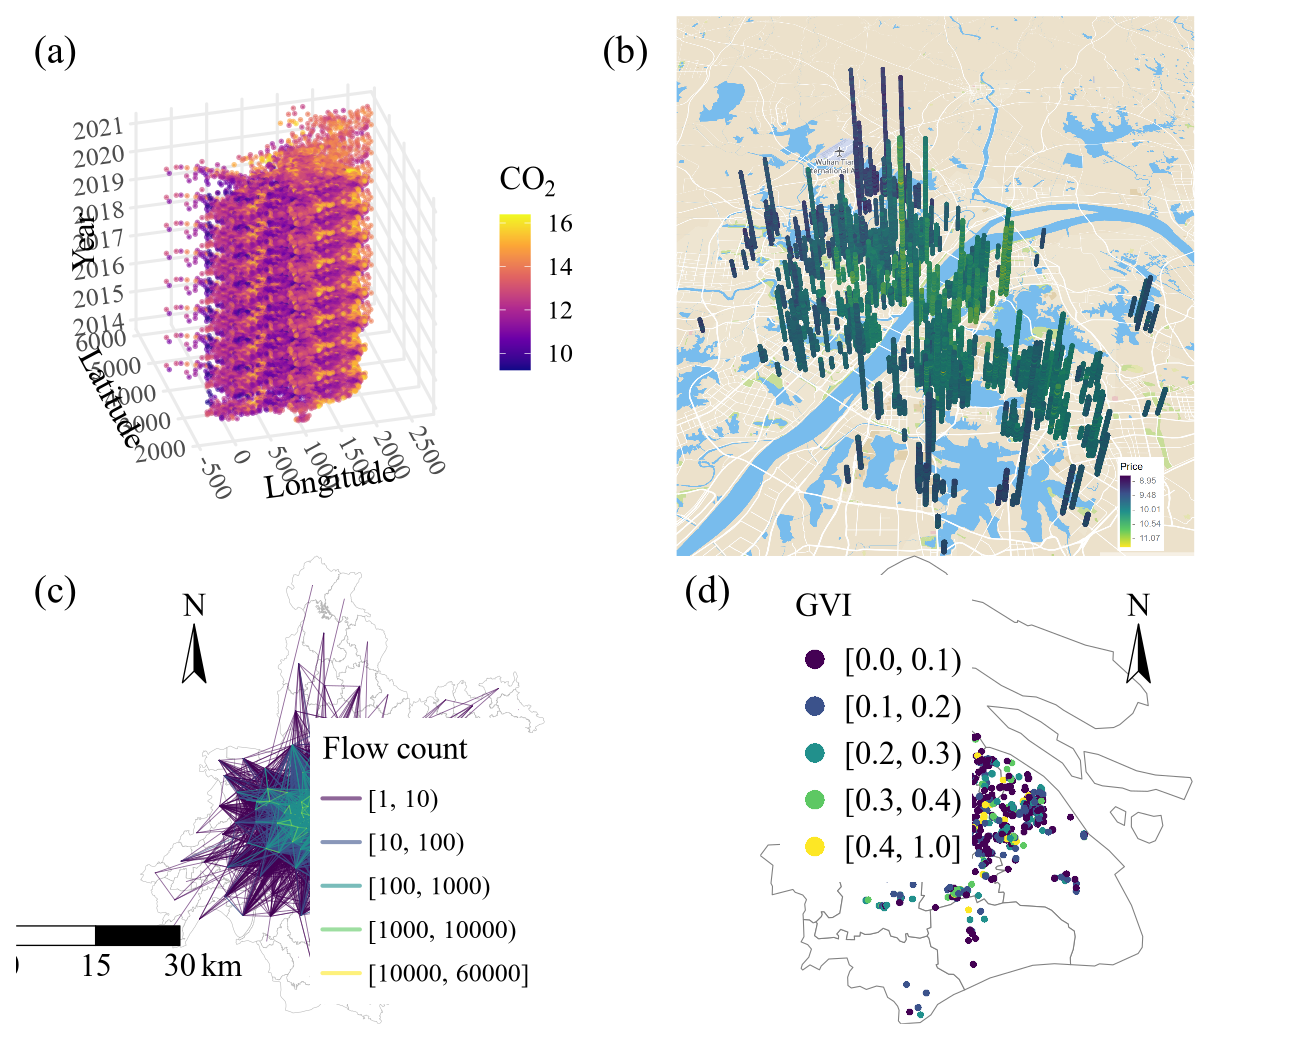

In [232]:
(fig_ce | fig_shp_panel) / (fig_sic_panel | fig_gvi_panel) +
  plot_annotation(
    tag_levels = "a",
    tag_prefix = "(",
    tag_suffix = ")",
    theme = theme(
      plot.tag = element_text(size = 20, face = "bold", family = "Times New Roman")
    )
  ) +
  plot_layout(
    widths = c(7,8)
  )

In [234]:
ggsave("../figures/data_visualisation.pdf", width = 15, height = 15, device = cairo_pdf)